In [85]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from pathlib import Path
import seaborn as sns
from pathlib import Path
import sys

from utils import pq_to_xy, plot_spatial_kernel_hex
from utils.spatial_RF import compute_kernel
from utils.plotting import plot_example_RFs, plot_kernels_on_eye, receptive_fields_grid


In [86]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar_T4T5norm.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar_T4T5norm.feather')

# edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
# nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')

print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


In [93]:
POST_TYPE = "T4c"
RADIUS    = 2
THRESHOLD = 1.0

# Choose what each matrix entry should contain
VALUE_COL = "signed_count"   # or "count", depending on your full-kernel columns

mean_kernels = {}
full_kernels = {}

POST_TYPE_inputs = edges.query("post_cell_type == @POST_TYPE").copy()
input_types = POST_TYPE_inputs["pre_cell_type"].unique()

# Compute per-input full kernels
for pre_type in input_types:
    mean_kernel, full = compute_kernel(
        edges,
        pre_type=pre_type,
        post_type=POST_TYPE,
        radius=RADIUS,
    )

    mean_kernels[pre_type] = mean_kernel
    full_kernels[pre_type] = full

In [94]:
### Filter out connections below threshold
kernel_strength = {
    pre_type: mean_kernels[pre_type]["mean_signed_count"].abs().max()
    for pre_type in input_types
}

input_types = [
    pre_type
    for pre_type in input_types
    if kernel_strength[pre_type] >= THRESHOLD
]

input_types = sorted(
    input_types,
    key=lambda pre_type: kernel_strength[pre_type],
    reverse=True
)
print("Strong input types: ", input_types)

Strong input types:  ['Mi1', 'Mi9', 'Mi4', 'CT1', 'T4c']


In [95]:
## Convert from matrix form back to df for plotting
def vector_to_kernel(vec, value_name="value"):
    rows = []
    for offsets, count in vec.items():
        dp, dq = offsets.split("_")
        rows.append({
            "dp": int(dp),
            "dq": int(dq),
            value_name: count,
        })

    return pd.DataFrame(rows)

/tmp/ipykernel_25505/377982443.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


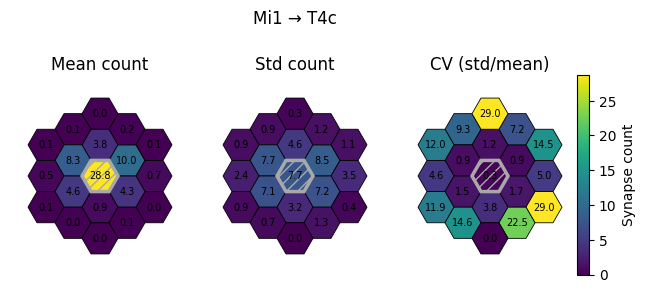

/tmp/ipykernel_25505/377982443.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


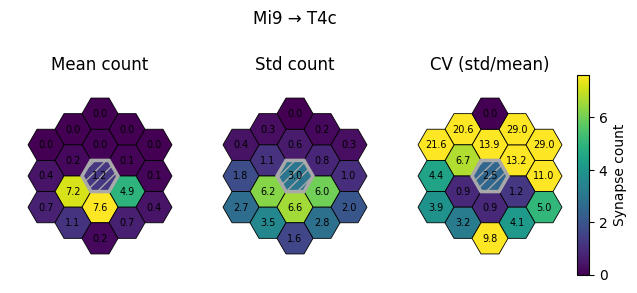

/tmp/ipykernel_25505/377982443.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


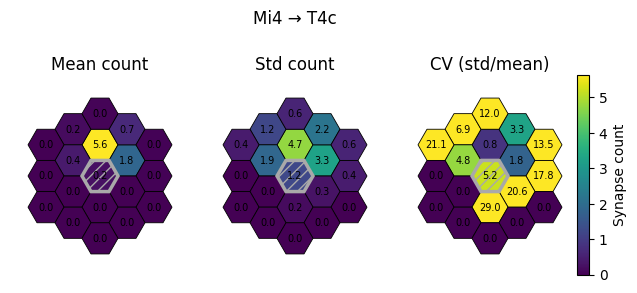

/tmp/ipykernel_25505/377982443.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


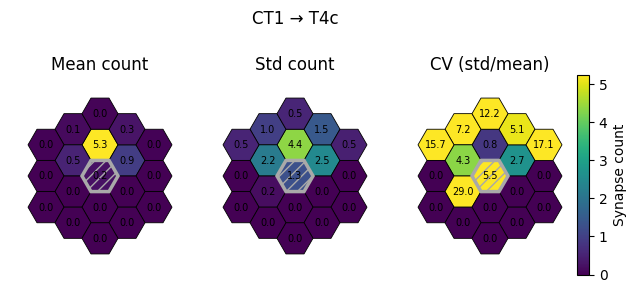

/tmp/ipykernel_25505/377982443.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


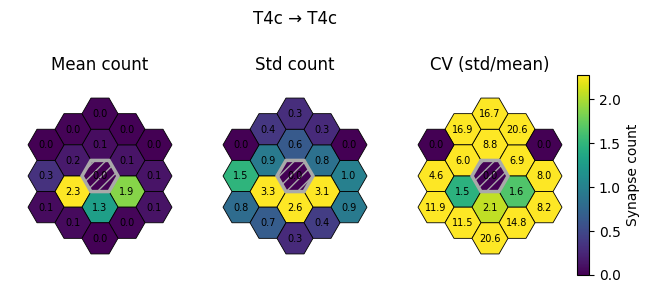

In [96]:
from matplotlib.colors import TwoSlopeNorm,  Normalize

for pre_type in input_types:
    pair_kernels = full_kernels[pre_type]
    pair_Matrix = (
            pair_kernels
            .assign(                    ##Creates new col called offset: converts the (dp,dq) pair into a col name
                offset=lambda d: (
                    d["dp"].astype(int).astype(str)
                    + "_"
                    + d["dq"].astype(int).astype(str)
                )
            )
            .pivot_table( #reshapes the long table into a wide matrix.
                index="post", #row per post
                columns="offset", #one col per offset
                values="count", #fills each col with summed counts
                aggfunc="sum", #If there are multiple rows with the same (post, offset), add their counts together. I think there should be few
                fill_value=0,
            ).rename_axis(columns=None)   # removes the "offset" label above columns
        # .reset_index()               # turns post from index into first column
        )


    mean_vec = pair_Matrix.mean(axis=0)
    std_vec = pair_Matrix.std(axis=0)
    var_vec = pair_Matrix.var(axis=0)
    cv_vec = std_vec / mean_vec.replace(0, np.nan)
    cv_vec = cv_vec.fillna(0)

    maps = {
        "Mean count": mean_vec,
        "Std count": std_vec,
        # "Variance (Sqrd units)": var_vec,
        "CV (std/mean)": cv_vec,
    }
    # norm = TwoSlopeNorm(
    #         vmin=-55,
    #         vcenter=0,
    #         vmax=55
    #     )

    norm = Normalize(vmin=0, vmax= mean_vec.max())
    CMAP = "viridis"

    fig, axes = plt.subplots(1,3,  figsize= (6,5))
    fig.suptitle(f"{pre_type} → {POST_TYPE}", y=0.8)
    axes = axes.ravel()  # turns 2x2 array into flat list of 4 axes
    for ax, (title, vec) in zip(axes, maps.items()):
        ax.axis("off")
        kernel = vector_to_kernel(vec, value_name="value")
        plot_spatial_kernel_hex(kernel, 
                                ax=ax, 
                                value_col="value", 
                                norm = norm,
                                cmap = CMAP,
                                radius=RADIUS)
        ax.set_title(title)

    # Common colorbar
    sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap(f"{CMAP}"))
    sm.set_array([])

    cax = fig.add_axes([0.97, 0.27, 0.02, 0.4]) # [left, bottom, width, height]
    cbar = fig.colorbar(
        sm,
        cax=cax,
        shrink=0.4,
        location="right",
        label="Synapse count"
    )

    fig.tight_layout()
    plt.show()